In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy import stats

In Pandas in pivote table, can't use average, instead we use mean or median.

Difference in groupby and pivot_table is groupby directly apply to DataFrame, while pivote_table is pandas method.

In [ ]:
dff=pd.read_csv('/content/Retail_Dataset_Cleaned.csv')

In [ ]:
dff.groupby(['Season','Weather_Impact'])[['Market_Share','Online_Rating']]

In [ ]:
dff.groupby(['Season','Weather_Impact'])[['Market_Share','Online_Rating']].sum()

Market_Share  Online_Rating
Season  Weather_Impact                             
Monsoon High                  1942.4          645.4
        Low                  20121.6         5531.5
        Medium                4153.8         1343.2
Spring  Low                  10052.4         2741.4
        Medium                2869.7          942.1
Summer  High                  3984.1         1290.9
        Low                  14300.5         3819.6
        Medium                1506.8          493.6
Winter  Low                  15772.6         4315.2
        Medium                4564.9         1492.3

In [ ]:
t = np.random.randint(1,6,size=len(dff))
print('len of t',len(t),'shape of dff',dff.shape)

len of t 5146 shape of dff (5146, 47)


In [ ]:
dff.columns

Index(['Store_ID', 'Store_Name', 'Brand_Name', 'Store_Type', 'City',
       'City_Tier', 'Product_Name', 'Category', 'Sub_Category',
       'Product_Stage', 'Quantity_Available', 'Units_Sold', 'Unit_Price',
       'Cost_Price', 'Revenue', 'Profit_Margin', 'Average_Order_Value',
       'Inventory_Turnover', 'Days_of_Stock', 'Customer_Segment',
       'Sales_Channel', 'Payment_Method', 'Supplier', 'Supplier_Rating',
       'Promotion_Type', 'Promotion_Impact', 'Max_Discount_Offered',
       'Return_Rate', 'Return_Reason', 'Customer_Satisfaction',
       'Online_Rating', 'Review_Count', 'Sales_Rep_Experience',
       'Sales_Rep_Rating', 'Market_Share', 'Competition_Level',
       'Competitor_Count', 'Brand_Loyalty', 'Brand_Awareness',
       'Price_Competitiveness', 'Weather_Impact', 'Delivery_Time',
       'Shipping_Cost', 'Month', 'Year', 'Quarter', 'Season'],
      dtype='object')

In [ ]:
dff.isnull().sum()

,0
Store_ID,0
Store_Name,0
Brand_Name,0
Store_Type,0
City,0
City_Tier,0
Product_Name,0
Category,0
Sub_Category,0
Product_Stage,0


In [ ]:
fg = pd.pivot_table(dff,values = "Profit_Margin" , index= "Season" , aggfunc= "sum" )
fg

,Profit_Margin
Season,
Monsoon,38290.71
Spring,18780.81
Summer,28777.85
Winter,29669.64


In [ ]:
rt = pd.pivot_table(dff,values = "Shipping_Cost" , index = ["Season","Weather_Impact"] ,
                    aggfunc= "median")
rt

Shipping_Cost
Season  Weather_Impact               
Monsoon High                    118.5
        Low                     130.0
        Medium                  102.0
Spring  Low                     136.0
        Medium                  102.0
Summer  High                    112.0
        Low                     126.0
        Medium                  100.5
Winter  Low                     135.0
        Medium                  100.0

In [ ]:
rt3 = pd.pivot_table(dff,values = "Shipping_Cost" , index = ["Season","Weather_Impact"] ,
                    aggfunc= ["sum" , "mean"])
rt3

sum          mean
                       Shipping_Cost Shipping_Cost
Season  Weather_Impact                            
Monsoon High                 29061.0    199.047945
        Low                 220102.0    174.822875
        Medium               30144.0     98.832787
Spring  Low                 118902.0    190.243200
        Medium               21664.0    101.708920
Summer  High                 56152.0    192.962199
        Low                 136429.0    156.995397
        Medium               11153.0     99.580357
Winter  Low                 184455.0    187.074037
        Medium               34377.0    101.108824

In [ ]:
rt5 = pd.pivot_table(dff,values = ["Shipping_Cost","Market_Share"] , index = ["Season","Weather_Impact"] ,
                    aggfunc= {"Shipping_Cost" : "median" ,"Market_Share" : "sum" })
rt5

Market_Share  Shipping_Cost
Season  Weather_Impact                             
Monsoon High                  1942.4          118.5
        Low                  20121.6          130.0
        Medium                4153.8          102.0
Spring  Low                  10052.4          136.0
        Medium                2869.7          102.0
Summer  High                  3984.1          112.0
        Low                  14300.5          126.0
        Medium                1506.8          100.5
Winter  Low                  15772.6          135.0
        Medium                4564.9          100.0

In [ ]:
dff.insert(2 ,"ratt" , t)

In [ ]:
dff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5146 entries, 0 to 5145
Data columns (total 48 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Store_ID               5146 non-null   object 
 1   Store_Name             5146 non-null   object 
 2   ratt                   5146 non-null   int64  
 3   Brand_Name             5146 non-null   object 
 4   Store_Type             5146 non-null   object 
 5   City                   5146 non-null   object 
 6   City_Tier              5146 non-null   object 
 7   Product_Name           5146 non-null   object 
 8   Category               5146 non-null   object 
 9   Sub_Category           5146 non-null   object 
 10  Product_Stage          5146 non-null   object 
 11  Quantity_Available     5146 non-null   float64
 12  Units_Sold             5146 non-null   float64
 13  Unit_Price             5146 non-null   int64  
 14  Cost_Price             5146 non-null   int64  
 15  Reve

In [ ]:
category_summary = pd.pivot_table(
    dff,
    values="Revenue",
    index="Category",
    aggfunc=["sum", "mean", "max", "min"]
)

category_summary

,sum,mean,max,min
,Revenue,Revenue,Revenue,Revenue
Category,,,,
Clothes,2.220630e+08,1.717425e+05,1245972.0,4985.0
Electronics,3.623063e+09,2.769926e+06,11182353.0,120655.0
Gadgets,2.654379e+09,2.594701e+06,23343582.0,9295.0
Groceries,2.394028e+07,2.365641e+04,350176.0,840.0
Home Appliances,5.584119e+08,1.094925e+06,6588592.0,81333.0


merge will work on pandas, not DataFrame. merge have join method like inner, left, right by using how parameter.

join have not this parameter and this will work on DataFrame.

In [ ]:
dff['ratt'].unique() #show all distinct values

array([1, 4, 3, 5, 2])

In [ ]:
dff['ratt'].nunique() #show how many distinct values

5

In [ ]:
d4 = dff[["Store_Name","ratt","Season"]].head(3)
d5 = dff[["Store_Name","ratt","Season"]].tail(3)

In [ ]:
d4

,Store_Name,ratt,Season
0,Brandx_India Superstore Pune,1,Spring
1,Brandx_India Superstore Mumbai,1,Spring
2,Brandx_India Trends Pune,4,Spring


In [ ]:
d5

,Store_Name,ratt,Season
5143,Brandx_India Gadget Zone Kanpur,5,Monsoon
5144,Brandx_India Style Mumbai,1,Winter
5145,Brandx_India Electronics Delhi,1,Monsoon


In [ ]:
we = d4.join(d5 , lsuffix= "core" , on= "ratt" )
we

,Store_Namecore,rattcore,Seasoncore,Store_Name,ratt,Season
0,Brandx_India Superstore Pune,1,Spring,NaN,NaN,NaN
1,Brandx_India Superstore Mumbai,1,Spring,NaN,NaN,NaN
2,Brandx_India Trends Pune,4,Spring,NaN,NaN,NaN


In [ ]:
pd.concat([d4,d5])

,Store_Name,ratt,Season
0,Brandx_India Superstore Pune,1,Spring
1,Brandx_India Superstore Mumbai,1,Spring
2,Brandx_India Trends Pune,4,Spring
5143,Brandx_India Gadget Zone Kanpur,5,Monsoon
5144,Brandx_India Style Mumbai,1,Winter
5145,Brandx_India Electronics Delhi,1,Monsoon


In [ ]:
pd.concat([d4,d5] , axis = 1)

,Store_Name,ratt,Season,Store_Name,ratt,Season
0,Brandx_India Superstore Pune,1.0,Spring,NaN,NaN,NaN
1,Brandx_India Superstore Mumbai,1.0,Spring,NaN,NaN,NaN
2,Brandx_India Trends Pune,4.0,Spring,NaN,NaN,NaN
5143,NaN,NaN,NaN,Brandx_India Gadget Zone Kanpur,5.0,Monsoon
5144,NaN,NaN,NaN,Brandx_India Style Mumbai,1.0,Winter
5145,NaN,NaN,NaN,Brandx_India Electronics Delhi,1.0,Monsoon


In [ ]:
pd.merge(d5,d4 ,on = "ratt" ,how = "left")

,Store_Name_x,ratt,Season_x,Store_Name_y,Season_y
0,Brandx_India Gadget Zone Kanpur,5,Monsoon,NaN,NaN
1,Brandx_India Style Mumbai,1,Winter,Brandx_India Superstore Pune,Spring
2,Brandx_India Style Mumbai,1,Winter,Brandx_India Superstore Mumbai,Spring
3,Brandx_India Electronics Delhi,1,Monsoon,Brandx_India Superstore Pune,Spring
4,Brandx_India Electronics Delhi,1,Monsoon,Brandx_India Superstore Mumbai,Spring


In [ ]:
idd = [1212 , 1515 , np.nan , 7878]
name = ["X","Y","Z",np.nan]
age = [np.nan , 2,7,np.nan]

In [ ]:
drr = pd.DataFrame({"IDD" : idd , "NAME" : name , "AGE" :age})
drr

,IDD,NAME,AGE
0,1212.0,X,NaN
1,1515.0,Y,2.0
2,NaN,Z,7.0
3,7878.0,NaN,NaN


In [ ]:
drr.isnull().sum()

,0
IDD,1
NAME,1
AGE,2


In [ ]:
drr.fillna(7777)

,IDD,NAME,AGE
0,1212.0,X,7777.0
1,1515.0,Y,2.0
2,7777.0,Z,7.0
3,7878.0,7777,7777.0


In [ ]:
drr

,IDD,NAME,AGE
0,1212.0,X,NaN
1,1515.0,Y,2.0
2,NaN,Z,7.0
3,7878.0,NaN,NaN


In [ ]:
drr.fillna(method = "ffill") #forward fill method

/tmp/ipykernel_2002/3747715755.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drr.fillna(method = "ffill") #forward fill method


,IDD,NAME,AGE
0,1212.0,X,NaN
1,1515.0,Y,2.0
2,1515.0,Z,7.0
3,7878.0,Z,7.0


In [ ]:
drr.fillna(method = "bfill") #backward fill method

/tmp/ipykernel_2002/2803424135.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drr.fillna(method = "bfill") #backward fill method


,IDD,NAME,AGE
0,1212.0,X,2.0
1,1515.0,Y,2.0
2,7878.0,Z,7.0
3,7878.0,NaN,NaN


In [ ]:
drr.fillna(method = "ffill" , axis = 1) #fill for column wise

/tmp/ipykernel_2002/3947197236.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drr.fillna(method = "ffill" , axis = 1) #fill for column wise
/tmp/ipykernel_2002/3947197236.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  drr.fillna(method = "ffill" , axis = 1) #fill for column wise


,IDD,NAME,AGE
0,1212.0,X,X
1,1515.0,Y,2.0
2,NaN,Z,7.0
3,7878.0,7878.0,7878.0


In [ ]:
drr.fillna(method = "bfill" , axis = 1)

/tmp/ipykernel_2002/3808997437.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  drr.fillna(method = "bfill" , axis = 1)
/tmp/ipykernel_2002/3808997437.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  drr.fillna(method = "bfill" , axis = 1)


,IDD,NAME,AGE
0,1212.0,X,NaN
1,1515.0,Y,2.0
2,Z,Z,7.0
3,7878.0,NaN,NaN


In [ ]:
df=pd.read_csv('/content/Retail_Dataset_Cleaned.csv')

In [ ]:
flagship = df[df["Store_Type"]=="Flagship"]["Customer_Satisfaction"]
flagship

,Customer_Satisfaction
0,4.0
2,4.3
21,4.3
23,4.6
24,3.8
...,...
5124,3.9
5135,3.9
5136,4.5
5143,3.9


In [ ]:
mall = df[df["Store_Type"]=="Mall Store"]["Customer_Satisfaction"]
mall

,Customer_Satisfaction
3,4.4
4,3.9
7,4.3
9,4.0
10,4.4
...,...
5123,3.9
5131,4.4
5132,3.7
5133,4.4


In [ ]:
t_stat, p_value = stats.ttest_ind(flagship,mall,nan_policy="omit")

print("T Statistic:", t_stat)
print("P Value:", p_value)

T Statistic: 0.5195690551232559
P Value: 0.6034184941873542


In [ ]:
if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Fail to Reject Null Hypothesis


In [2]:
df = pd.read_csv("/content/Retail_Dataset_Cleaned.csv")
df

,Store_ID,Store_Name,Brand_Name,Store_Type,City,City_Tier,Product_Name,Category,Sub_Category,Product_Stage,...,Brand_Loyalty,Brand_Awareness,Price_Competitiveness,Weather_Impact,Delivery_Time,Shipping_Cost,Month,Year,Quarter,Season
0,Bx_Pune_034,Brandx_India Superstore Pune,Brandx_India,Flagship,Pune,Tier1,Green Tea 100G,Groceries,Tea,Declining,...,70.8,75.7,Standard,Low,6.0,57.0,1,2022,Q1,Spring
1,Bx_Mumbai_023,Brandx_India Superstore Mumbai,Brandx_India,Street Store,Mumbai,Metro,White Sugar 1Kg,Groceries,Sugar,Declining,...,80.5,81.5,Competitive,Low,4.0,99.0,1,2022,Q1,Spring
2,Bx_Pune_073,Brandx_India Trends Pune,Brandx_India,Flagship,Pune,Tier1,Levi'S T-Shirt,Clothes,T-Shirts,Declining,...,68.5,76.7,Standard,Medium,4.0,101.0,1,2022,Q1,Spring
3,Bx_Chennai_061,Brandx_India Trends Chennai,Brandx_India,Mall Store,Chennai,Metro,Adidas Hoodie,Clothes,Jackets,New Launch,...,92.4,88.0,Competitive,Medium,5.0,79.0,1,2022,Q1,Spring
4,Bx_Chennai_033,Brandx_India Connect Chennai,Brandx_India,Mall Store,Chennai,Metro,Playstation 5,Gadgets,Gaming Consoles,Declining,...,82.9,89.5,Competitive,Low,2.0,110.0,1,2022,Q1,Spring
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5141,Bx_Jaipur_077,Brandx_India Style Jaipur,Brandx_India,Street Store,Jaipur,Tier2,Pepe Jeans,Clothes,Jeans,Declining,...,91.3,68.7,Standard,Medium,3.0,150.0,11,2024,Q4,Winter
5142,Bx_Mumbai_067,Brandx_India Daily Mumbai,Brandx_India,Express,Mumbai,Metro,White Sugar 1Kg,Groceries,Sugar,Growing,...,81.6,82.0,Competitive,Low,7.0,136.0,7,2023,Q3,Monsoon
5143,Bx_Kanpur_097,Brandx_India Gadget Zone Kanpur,Brandx_India,Flagship,Kanpur,Tier2,Dell Xps 13,Electronics,Laptops,Discontinued,...,89.9,68.1,Standard,Low,1.0,222.0,7,2023,Q3,Monsoon
5144,Bx_Mumbai_031,Brandx_India Style Mumbai,Brandx_India,Street Store,Mumbai,Metro,Nike Air Max,Clothes,Shoes,Mature,...,80.6,86.5,Competitive,Medium,3.0,138.0,12,2022,Q4,Winter


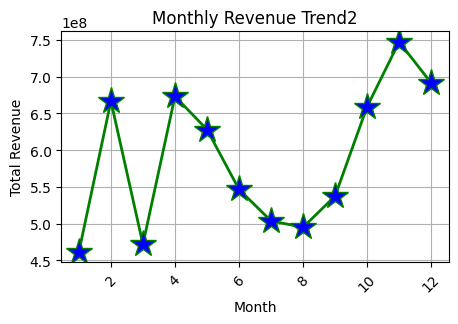

In [3]:
monthly_revenue = df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(5, 3))
plt.plot(monthly_revenue.index,monthly_revenue.values,marker='*',markersize = 20,
  linewidth=2 , color = "green" , markerfacecolor = "blue")

plt.title('Monthly Revenue Trend2')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

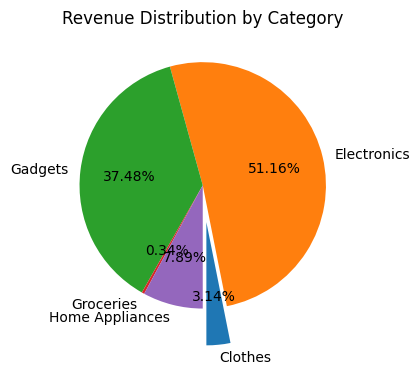

In [5]:
category_revenue = df.groupby('Category')['Revenue'].sum()

# Create Pie Chart
plt.figure(figsize=(4, 4))

plt.pie(category_revenue,
        labels=category_revenue.index,
        autopct='%1.2f%%',
        startangle=270 , explode = [0.3,0,0,0,0])

plt.title('Revenue Distribution by Category')

plt.show()

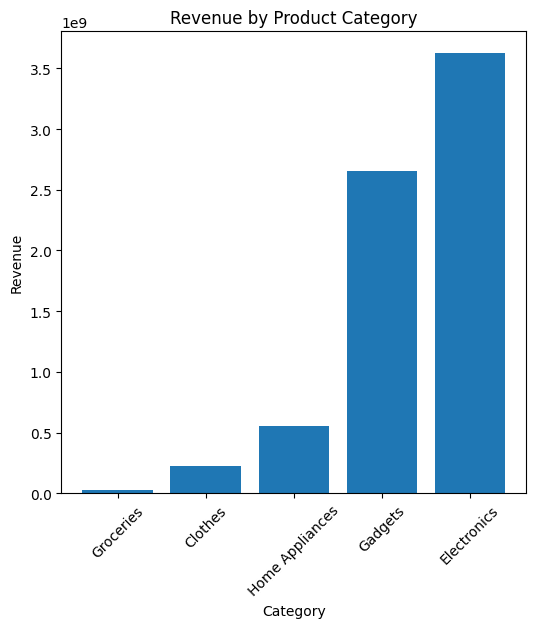

In [6]:
category_revenue = df.groupby('Category')['Revenue'].sum().sort_values()

plt.figure(figsize=(6, 6))
plt.bar(category_revenue.index,
        category_revenue.values)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Category', ylabel='Revenue'>

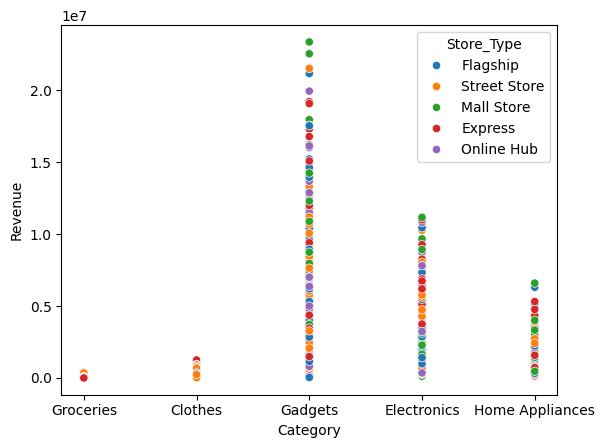

In [7]:
sns.scatterplot(x = 'Category' , y = 'Revenue' , data = df , hue = 'Store_Type' )

<Axes: xlabel='Category', ylabel='Revenue'>

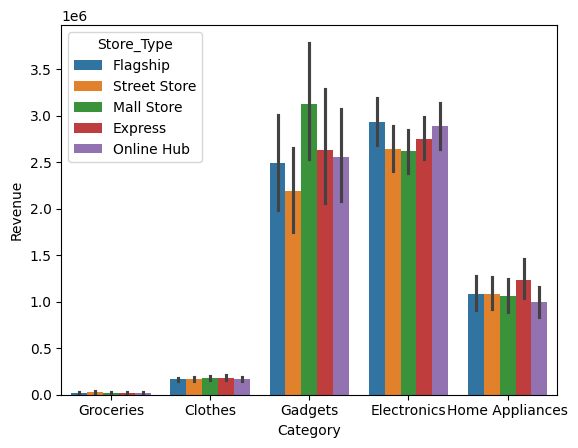

In [8]:
sns.barplot(x = 'Category' , y = 'Revenue' , data = df , hue = 'Store_Type' )

<Axes: xlabel='Category', ylabel='Revenue'>

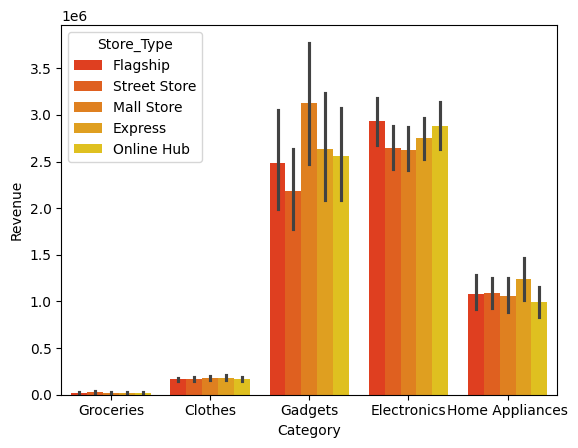

In [9]:
sns.barplot(x = 'Category' , y = 'Revenue' , data = df , hue = 'Store_Type'  , palette= "autumn")

<Axes: xlabel='Category', ylabel='Revenue'>

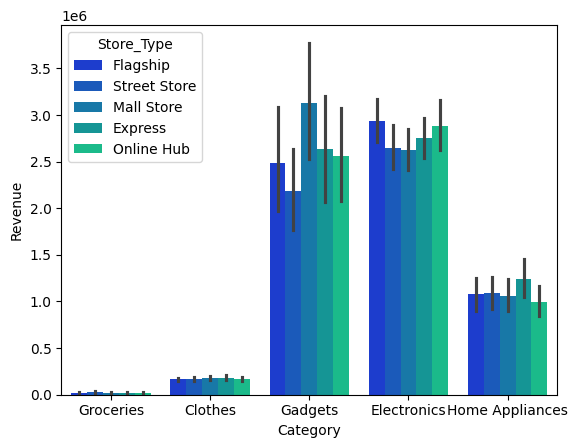

In [10]:
sns.barplot(x = 'Category' , y = 'Revenue' , data = df , hue = 'Store_Type'  , palette= "winter")

(array([4497.,  448.,  117.,   46.,   22.,   10.,    6.]),
 array([8.40000000e+02, 3.33551743e+06, 6.67019486e+06, 1.00048723e+07,
        1.33395497e+07, 1.66742271e+07, 2.00089046e+07, 2.33435820e+07]),
 <BarContainer object of 7 artists>)

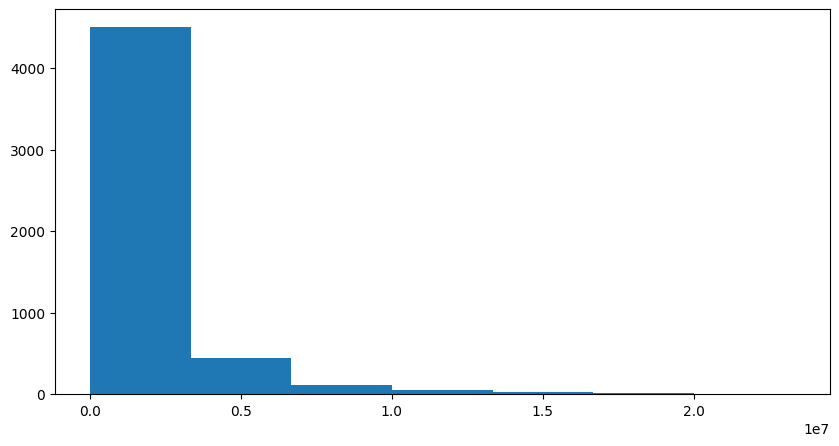

In [11]:
plt.figure(figsize=(10, 5))
plt.hist(df['Revenue'],bins=7)

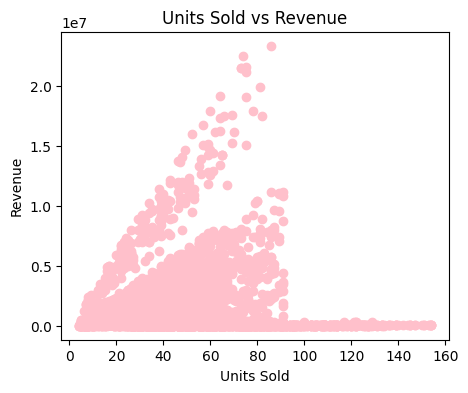

In [12]:
plt.figure(figsize=(5, 4))
plt.scatter(df['Units_Sold'],df['Revenue'] , c = "pink")
plt.title('Units Sold vs Revenue')
plt.xlabel('Units Sold')
plt.ylabel('Revenue')

plt.show()

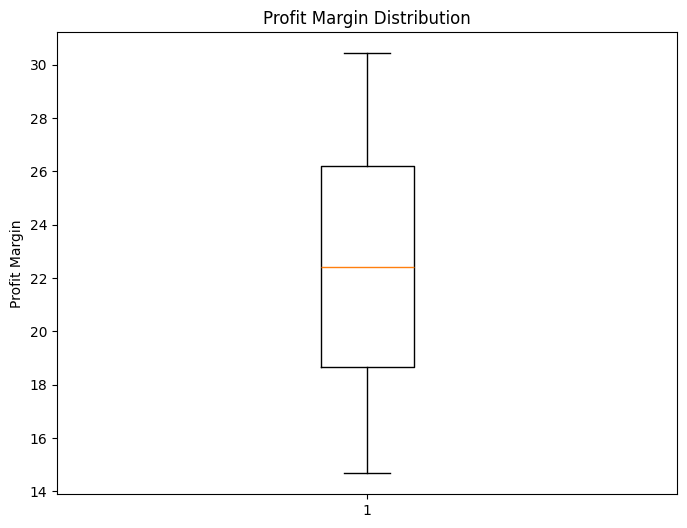

In [13]:
plt.figure(figsize=(8, 6))
plt.boxplot(df['Profit_Margin'])
plt.title('Profit Margin Distribution')
plt.ylabel('Profit Margin')
plt.show()

Text(0.5, 1.0, 'Count of Products by Category')

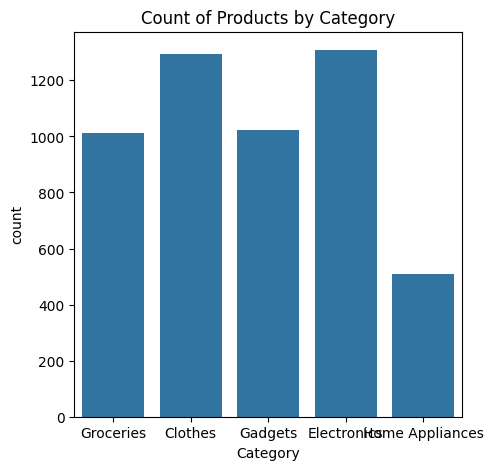

In [14]:
plt.figure(figsize=(5, 5))

sns.countplot(data=df, x='Category')

plt.title('Count of Products by Category')

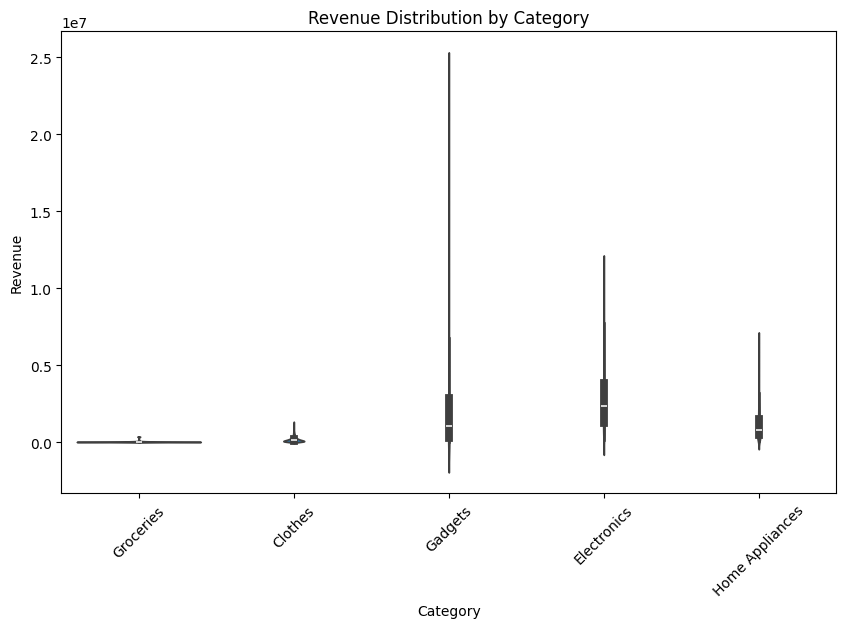

In [15]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=df,x='Category', y='Revenue')

plt.title('Revenue Distribution by Category')
plt.xticks(rotation=45)

plt.show()

In [16]:
# Calculate correlation matrix
corr = df.select_dtypes(include='number').corr()

# Increase figure size
plt.figure(figsize=(18, 12))

<Figure size 1800x1200 with 0 Axes>

<Figure size 1800x1200 with 0 Axes>

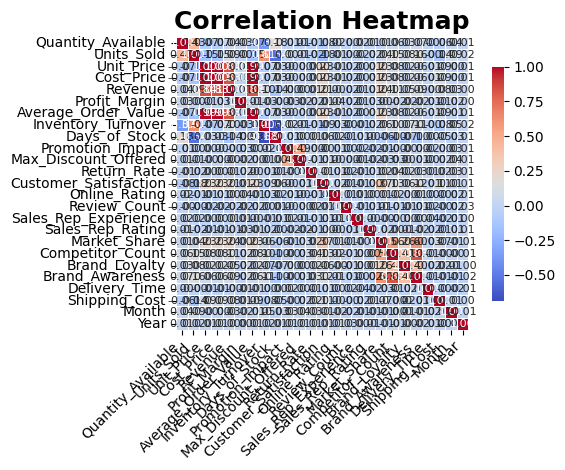

In [17]:
# Create heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    annot_kws={'size': 8},
    square=True,
    cbar_kws={'shrink': 0.8}
)

# Customize chart
plt.title('Correlation Heatmap', fontsize=18, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

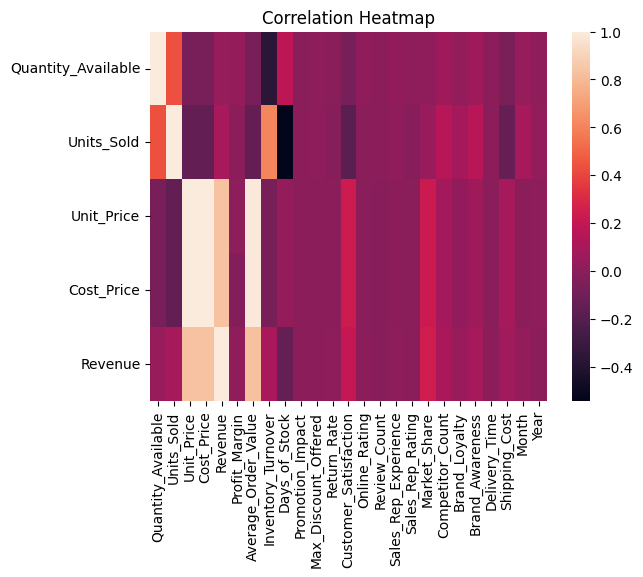

In [18]:
sns.heatmap(corr.head(5),annot=False)

plt.title('Correlation Heatmap')
plt.xticks()
plt.yticks()
plt.show()

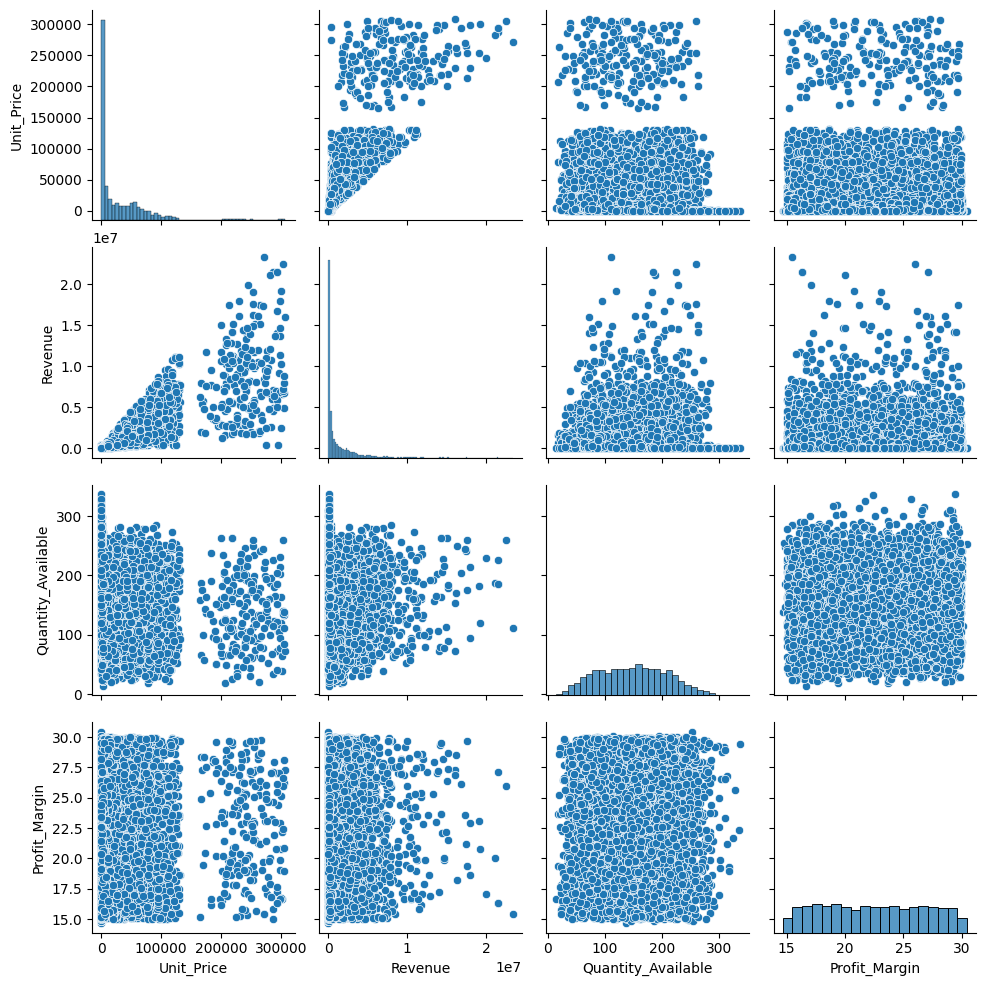

In [19]:
sns.pairplot(df[['Unit_Price',
                 'Revenue',
                 'Quantity_Available',
                 'Profit_Margin']])

plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 72.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 83.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 77.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 87.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 64.0% of the points cannot be plac

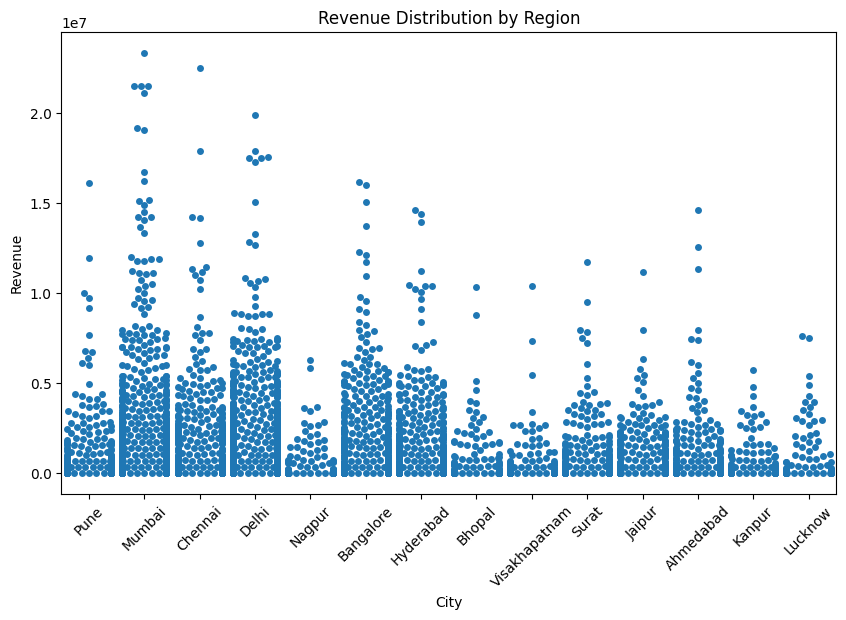

In [20]:
plt.figure(figsize=(10, 6))

sns.swarmplot(data=df,
              x='City',
              y='Revenue')

plt.title('Revenue Distribution by Region')
plt.xticks(rotation=45)

plt.show()

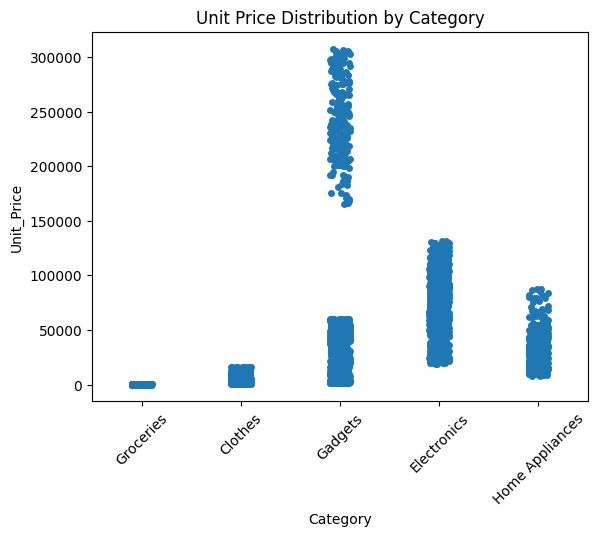

In [21]:
sns.stripplot(data=df,
              x='Category',
              y='Unit_Price',
              jitter=True)

plt.title('Unit Price Distribution by Category')
plt.xticks(rotation=45)

plt.show()

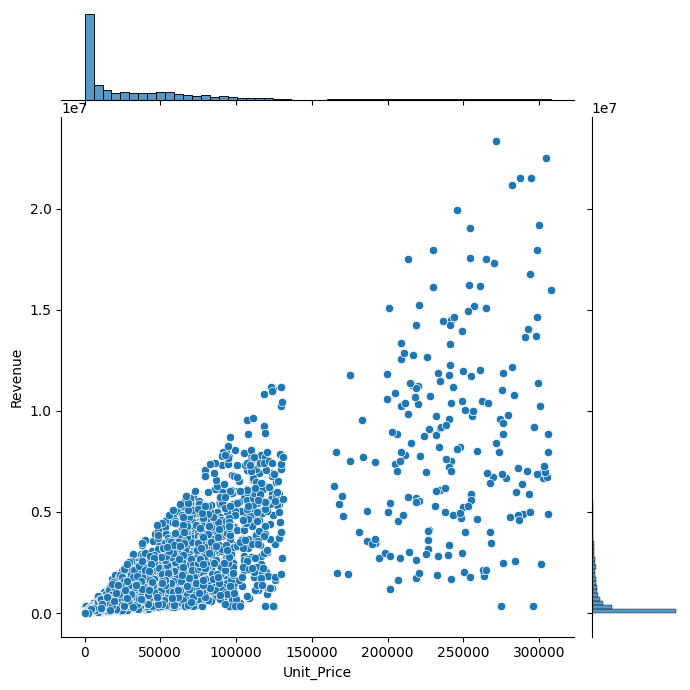

In [22]:
sns.jointplot(data=df,
              x='Unit_Price',
              y='Revenue',
              kind='scatter',
              height=7)

plt.show()

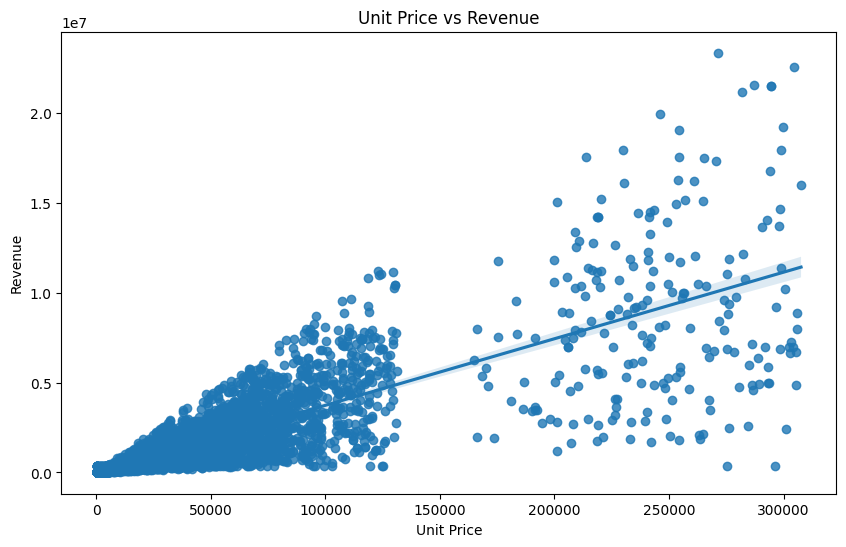

In [23]:
plt.figure(figsize=(10, 6))

sns.regplot(data=df,
            x='Unit_Price',
            y='Revenue')

plt.title('Unit Price vs Revenue')
plt.xlabel('Unit Price')
plt.ylabel('Revenue')

plt.show()

Text(0, 0.5, 'Total Revenue')

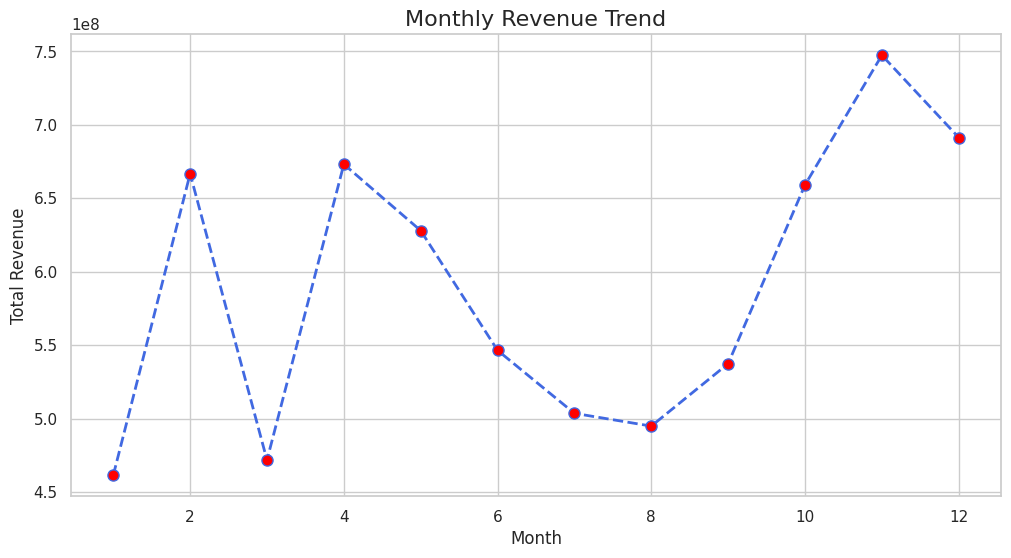

In [24]:
# Apply Seaborn Theme
sns.set_theme(style="whitegrid")

# Prepare Data
monthly_revenue = df.groupby('Month')['Revenue'].sum()

# Change Figure Size
plt.figure(figsize=(12, 6))

# Create Line Chart with Color, Marker, and Line Style
plt.plot(monthly_revenue.index,
         monthly_revenue.values,
         color='royalblue',
         marker='o',markerfacecolor='red',
         linestyle='--',
         linewidth=2,
         markersize=8,
         label='Revenue')

# Add Title
plt.title('Monthly Revenue Trend', fontsize=16)

# Add X-axis and Y-axis Labels
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)